# Research Methods for AI & Data Science: Research Methodology and Literature Review

> **Who is this for:** anyone starting an MS/MPhil thesis (or a first research project) in AI, ML or data science, and anyone who has to read, judge or write research papers at work. You do not need any research experience: every term is explained from zero.
>
> **What you will learn:**
> - what research is, the main types of research and the scientific method
> - how to write a good research question (FINER), hypotheses, objectives and a contribution statement
> - where to find AI literature in 2026 (and which services have changed or shut down), how to write Boolean search strings and how to snowball citations
> - how to read a paper with the three-pass method, summarise it and spot weak evidence
> - how to build a **literature review matrix** in pandas, synthesise it by theme and find the research gap
> - systematic reviews and the **PRISMA 2020** flow diagram, with counts computed from data
> - reference managers and BibTeX (with a tiny BibTeX parser written from scratch)
> - research ethics, including the responsible use of AI writing assistants
> - how an MS/MPhil proposal (synopsis) is structured, plus a Gantt-chart timeline in matplotlib
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [pandas](../02_Data_Analysis/03_pandas.ipynb) and [matplotlib](../02_Data_Analysis/04_matplotlib.ipynb). Hypothesis testing is explained again here in plain words; the full statistics lessons are in [Statistics for Data Science](../02_Data_Analysis/08_statistics.ipynb) and [Statistics for ML](../14_Mathematics/04_statistics.ipynb).
>
> **Time needed:** about 2–3 hours (reading + running + practice problems).
>
> **Runs on:** CPU, no API key, no internet needed (all papers and records are made up for practice).
>
> **Optional track:** part of the university-level fundamentals track; recommended for BS/MS AI students, thesis students and interview prep.

### The notebooks in this module

| # | Notebook | Main question it answers |
|---|---|---|
| 1 | **Research methodology and literature review** (this one) | *What* should I study, and what is already known? |
| 2 | [Experiment design for ML](02_experiment_design_for_ml.ipynb) | *How* do I run a fair, convincing experiment? |
| 3 | [Statistical significance and reporting](03_statistical_significance_and_reporting.ipynb) | Is my improvement *real*, and how do I report it honestly? |
| 4 | [Reproducibility and research code](04_reproducibility_and_research_code.ipynb) | Can someone else (or future me) get the same results? |
| 5 | [Paper writing and publishing](05_paper_writing_and_publishing.ipynb) | How do I write it up and get it published? |
| 6 | [Industry project: a research project end to end](06_industry_running_a_research_project_end_to_end.ipynb) | How does it all fit together in practice? |

### Table of contents
1. What research is (types, the scientific method, paradigms)
2. Writing a research question (FINER, hypotheses, objectives, scope, contribution)
3. Finding literature (databases in 2026, Boolean search, snowballing)
4. Reading papers (three-pass method, summary template, weak evidence)
5. The literature review matrix (synthesis, gap, timeline)
6. Systematic reviews and PRISMA 2020
7. Reference managers and BibTeX
8. Research ethics
9. The MS/MPhil proposal (synopsis) and a Gantt chart
10. How this connects to modern AI, recap, practice problems, further reading

## Explained simply

Research means finding out something nobody knew before, in a careful way that other people can check. Before you start, you need one sharp question, and you need to know what others have already found, so you do not spend months repeating them. A literature review is like reading every review of a phone before buying one: you learn what is good, what is weak and what nobody has tested yet. Finding papers is like a detective following clues: one good paper points to the older papers it cites and to the newer papers that cite it. Research ethics means playing fair: give credit to others, ask people's permission before using their data, and never invent results. Finally, a proposal is your plan with a timeline, just like planning a wedding with a list of tasks, people and dates.

**A tiny example.** You read 10 articles about cricket bats. 6 test English-willow bats and 4 test Kashmir-willow bats, but **none** test bats for players under 15. That empty spot is a **research gap**. Your research question could be: *"Do Kashmir-willow bats give under-15 players the same hitting distance as English-willow bats, measured over 50 shots each?"* It is specific, you can measure it, and nobody has answered it yet.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Research question | the exact thing you want to find out | "Does model X detect Urdu fake news better than model Y?" |
| Literature review | reading what others found and spotting what is missing | the "Related work" section of every AI paper |
| Research gap | an important spot nobody has studied yet | "nobody has tried LLM prompting for Urdu fake news" |

In [1]:
# Standard setup used throughout the notebook
import re                                  # regular expressions (search strings, BibTeX parsing)
import tempfile                            # temporary folders for files we write
import shutil                              # to delete the temporary folder at the end
from pathlib import Path                   # convenient file paths
from dataclasses import dataclass, field   # a tidy way to describe a paper summary
from datetime import date, timedelta       # dates for the Gantt chart

import numpy as np                         # numbers and random generators
import pandas as pd                        # tables (the literature matrix)
import matplotlib.pyplot as plt            # plots
import networkx as nx                      # citation graphs for snowballing

rng = np.random.default_rng(42)            # one seeded generator => same results every run
pd.set_option("display.width", 140)        # wide tables print on one line
pd.set_option("display.max_colwidth", 60)  # but keep long text readable
print("numpy", np.__version__, "| pandas", pd.__version__, "| networkx", nx.__version__)

numpy 2.4.6 | pandas 2.3.3 | networkx 3.7


## 1. What is research?

> **In plain English:** Research is careful, checkable finding-out; this section names the main kinds.

**Intuition.** Imagine you are a detective. You notice something puzzling ("why does our spam filter fail on Roman Urdu messages?"), you collect clues, you form a guess, you test the guess, and you write a report that other detectives can check. Research is the same thing done *systematically* and *in public*.

**Definition.** **Research** is a *systematic*, *documented* investigation that produces *new, verifiable* knowledge and shares it so others can check and build on it. Three words matter:

| Word | Meaning | What it rules out |
|---|---|---|
| systematic | you follow a plan (method) that you can describe | random tinkering you cannot repeat |
| new | it adds something not already known (a new fact, method, dataset, or a confirmation/refutation) | re-doing a tutorial |
| verifiable | someone else can check it (data, code, enough detail) | "trust me, it works" |

### 1.1 Types of research

Research is classified along several independent axes. One study has a value on **each** axis.

| Axis | Type | Plain-English meaning | AI / data-science example |
|---|---|---|---|
| **Purpose** | **Basic (fundamental)** | understand *why* something happens; no immediate product | Why do transformers learn in-context? |
| | **Applied** | solve a practical problem | Build an Urdu fake-news detector for a newsroom |
| **Data type** | **Quantitative** | numbers, measurements, statistics | Compare F1 of 5 models over 10 seeds |
| | **Qualitative** | words, meanings, interviews, themes | Interview 12 journalists about how they verify news |
| | **Mixed methods** | both, combined on purpose | Measure model accuracy *and* interview users about trust |
| **Source of evidence** | **Empirical** | evidence comes from observation or experiment | Run experiments on a benchmark |
| | **Theoretical** | evidence comes from proofs, derivations, logic | Prove a generalisation bound |
| **Depth of question** | **Exploratory** | "what is going on?" for a new topic; few prior studies | First look at LLM errors on Pashto text |
| | **Descriptive** | "what / how much / how often?" | How many Urdu NLP datasets exist, by task? |
| | **Explanatory (causal)** | "why / what causes what?" | Does data augmentation *cause* the F1 gain? (ablation) |

Most ML theses are **applied, quantitative, empirical** and move from **descriptive** (benchmarking) to **explanatory** (ablations that show *why* a method helps).

> ⚠️ **Common mistake:** writing "this is a qualitative study" because the thesis has few numbers. *Qualitative* is a method with its own rigour (coding interviews, thematic analysis, saturation), not "quantitative but weaker".

### 1.2 The scientific method (the research cycle)

```
   observe a puzzle ──► read the literature ──► ask a question ──► state a hypothesis
          ▲                                                              │
          │                                                              ▼
   publish & let others  ◄── draw conclusions ◄── analyse data ◄── design & run an experiment
   check / replicate          (support or reject)   (statistics)       (notebook 2)
```

The arrow from "publish" back to "observe" is the most important one: science is a loop. A single study never "proves" a claim; it adds evidence for or against it.

**Falsifiability** (Karl Popper): a good hypothesis must be able to *fail*. "Our model is better in some settings" cannot fail; "our model has higher macro-F1 than XLM-R on the test split of dataset D, averaged over 5 seeds" can.

### 1.3 Research paradigms (briefly)

A **paradigm** is the set of beliefs about what counts as knowledge and how to get it. You only need the names and one line each for a thesis methodology chapter.

| Paradigm | Belief about reality | Typical methods | Where you see it in AI |
|---|---|---|---|
| **Positivism / post-positivism** | there is one measurable reality; we approximate it (post-positivism admits error) | experiments, statistics | almost all benchmark-driven ML papers |
| **Interpretivism (constructivism)** | reality is constructed by people; understand meanings | interviews, ethnography | HCI studies of how people use chatbots |
| **Pragmatism** | use whatever method answers the question | mixed methods | user studies + offline metrics |
| **Critical / transformative** | research should expose power and inequality | participatory, critical analysis | algorithmic fairness and data-justice work |

> 🎓 **Exam / interview tip:** "Basic vs applied" is about *purpose*; "quantitative vs qualitative" is about *data*; "empirical vs theoretical" is about *evidence*. A question like "is a user study of chatbot trust basic or qualitative?" mixes two axes: it can be applied **and** qualitative at the same time.

In [2]:
# Classify a few made-up study descriptions on the four axes, as a quick self-check table
studies = [
    ("Prove a convergence rate for a new optimiser",                 "basic",   "quantitative", "theoretical", "explanatory"),
    ("Benchmark 6 Urdu sentiment models on 3 datasets",              "applied", "quantitative", "empirical",   "descriptive"),
    ("Interview 15 radiologists about AI triage tools",              "applied", "qualitative",  "empirical",   "exploratory"),
    ("Ablate each module of a RAG system to see which one helps",    "applied", "quantitative", "empirical",   "explanatory"),
    ("Survey logs + interviews on why users abandon a chatbot",      "applied", "mixed",        "empirical",   "explanatory"),
]
cols = ["study", "purpose", "data", "evidence", "depth"]          # one column per axis
types_df = pd.DataFrame(studies, columns=cols)                     # build the table
print(types_df.to_string(index=False))                             # print without the row index
print("\nCounts on the 'data' axis:", types_df["data"].value_counts().to_dict())

                                                    study purpose         data    evidence       depth
             Prove a convergence rate for a new optimiser   basic quantitative theoretical explanatory
          Benchmark 6 Urdu sentiment models on 3 datasets applied quantitative   empirical descriptive
          Interview 15 radiologists about AI triage tools applied  qualitative   empirical exploratory
Ablate each module of a RAG system to see which one helps applied quantitative   empirical explanatory
  Survey logs + interviews on why users abandon a chatbot applied        mixed   empirical explanatory

Counts on the 'data' axis: {'quantitative': 3, 'qualitative': 1, 'mixed': 1}


**What just happened?** Each study got one label on **each** of the four axes. Notice that the same study can be *applied* and *explanatory*, or *applied* and *qualitative*: the axes are independent. Three of the five are quantitative, one qualitative and one mixed.

## 2. Writing a research question

> **In plain English:** A good question is small, specific and measurable; a vague question gives a vague thesis.

**Intuition.** A research question is the *steering wheel* of the thesis. Every chapter, experiment and plot must help answer it. A vague question gives a vague thesis.

**Definition.** A **research question (RQ)** is a precise, answerable question that the study is designed to answer. Most MS theses have 1 main RQ and 2–4 sub-questions.

### 2.1 The FINER criteria

**FINER** (Hulley et al., *Designing Clinical Research*) is a checklist for a good RQ:

| Letter | Criterion | Ask yourself | AI-thesis example of failing it |
|---|---|---|---|
| **F** | **Feasible** | Can I answer it with my time, data, compute and skills? | "Pre-train a 70B-parameter Urdu LLM" on one laptop in 6 months |
| **I** | **Interesting** | Do my supervisor and the community care about the answer? | "Does accuracy change if I rename variables?" |
| **N** | **Novel** | Does it confirm, refute or extend previous findings? | Re-running a 2019 paper unchanged with no new angle |
| **E** | **Ethical** | Can it be done without harming people or breaking consent/licences? | Scraping private WhatsApp groups for a dataset |
| **R** | **Relevant** | Will the answer matter for science, practice or policy? | A metric nobody uses on a dataset nobody uses |

### 2.2 Good vs bad research questions

| Bad question | Why it is bad | Better question |
|---|---|---|
| "Can AI detect fake news?" | already answered (yes, sometimes); not specific; not measurable | "Does fine-tuning a multilingual transformer on 2,000 machine-translated Urdu examples improve macro-F1 over a TF-IDF + logistic-regression baseline on the [dataset] test split?" |
| "What is the best model for Urdu NLP?" | "best" for what task, metric, budget? | "Which of 4 open models under 1B parameters gives the highest accuracy per GPU-hour on Urdu news classification?" |
| "How can we use LLMs in healthcare?" | far too broad (a whole field) | "How often do two open 7B-parameter LLMs produce clinically wrong dosage advice on 300 pharmacist-written questions, as judged by 3 pharmacists?" |
| "Prove that our method is better." | assumes the answer; not falsifiable as written | "Is method M's improvement over baseline B statistically significant across 10 datasets (Friedman + Nemenyi, α = 0.05)?" |
| "Study bias in AI." | no population, variable or measure | "Does the false-positive rate of toxicity classifier T differ between Roman-Urdu and English comments with the same meaning?" |

A practical template: **"Does/How much does [intervention X] change [measurable outcome Y] for [population/data Z] compared with [comparison C], under [conditions]?"** This is the **PICO** idea from medicine (Population, Intervention, Comparison, Outcome) translated to ML.

### 2.3 Hypotheses and objectives

- A **hypothesis** is a testable prediction that answers the RQ before you run the study.
  - **Null hypothesis H0:** "no effect / no difference" (e.g. *the transformer and the baseline have the same expected macro-F1*).
  - **Alternative hypothesis H1:** what you expect if H0 is false (e.g. *the transformer has higher expected macro-F1*). One-sided (">") or two-sided ("≠").
- **Objectives** are the concrete *actions* you will take to answer the RQ. Write them with action verbs and make them **SMART** (Specific, Measurable, Achievable, Relevant, Time-bound):
  1. *To build* a cleaned Urdu fake-news dataset of ≥ 5,000 labelled articles by month 3.
  2. *To compare* 4 models under an equal tuning budget with 5 seeds each by month 6.
  3. *To analyse* which components matter through an ablation study by month 7.

> ⚠️ **Common mistake:** writing objectives that are just the RQ again ("to know whether…"). Objectives are steps; the RQ is the question.

### 2.4 Scoping

**Scope** says what is *in* and what is *out*. **Delimitations** are boundaries you choose ("only Urdu news, 2018–2025, text only"); **limitations** are weaknesses you cannot avoid ("labels from one annotator agency"). Write both; examiners always ask.

### 2.5 The novelty / contribution statement

A **contribution statement** lists, in 2–4 bullets, exactly what is new. Reviewers look for it in the introduction. Typical contribution types in AI:

| Contribution type | Example sentence |
|---|---|
| new dataset / benchmark | "We release UrduFact-5k, 5,000 fact-checked Urdu articles with a documented datasheet." |
| new method | "We propose X, which ... and improves macro-F1 by 3.1 points (95% CI 1.8–4.4)." |
| empirical study | "We show that 4 of 6 published gains vanish under an equal tuning budget." |
| analysis / negative result | "We find that translation-based augmentation does not help when ..." |
| tool / reproducibility | "We release code, seeds and configs to reproduce every table." |

The code below turns these rules into a tiny **FINER/PICO checker**. It is only a teaching toy (a real check needs a human), but it shows what a reviewer looks for.

In [3]:
# A toy research-question checker: looks for the ingredients of a specific, testable RQ
def check_rq(rq: str) -> dict:
    text = rq.lower()                                              # case-insensitive matching
    checks = {
        "is a question":        rq.strip().endswith("?"),          # an RQ should be a question
        "names a comparison":   any(w in text for w in ["compared", "than", " vs", "over"]),   # C in PICO
        "names a metric":       any(w in text for w in ["f1", "accuracy", "auc", "error", "rate", "bleu", "precision", "recall"]),  # O
        "names data/population": any(w in text for w in ["dataset", "split", "test", "comments", "articles", "questions", "patients"]),  # P
        "avoids vague words":   not any(w in text for w in ["best", "better ai", "use ai", "study bias", "can ai"]),
        "not too long":         len(rq.split()) <= 45,             # a readable RQ fits in one breath
    }
    checks["score (of 6)"] = sum(checks.values())                   # True counts as 1
    return checks

candidates = [
    "Can AI detect fake news?",
    "What is the best model for Urdu NLP?",
    "Does fine-tuning a multilingual transformer improve macro-F1 over a TF-IDF baseline on the Urdu news test split?",
    "Does the false-positive rate of a toxicity classifier differ between Roman-Urdu and English comments with the same meaning?",
]
rq_table = pd.DataFrame({rq[:55] + ("..." if len(rq) > 55 else ""): check_rq(rq) for rq in candidates}).T
print(rq_table.to_string())

                                                           is a question names a comparison names a metric names data/population avoids vague words not too long score (of 6)
Can AI detect fake news?                                            True              False          False                 False              False         True            2
What is the best model for Urdu NLP?                                True              False          False                 False              False         True            2
Does fine-tuning a multilingual transformer improve mac...          True               True           True                  True               True         True            6
Does the false-positive rate of a toxicity classifier d...          True              False           True                  True               True         True            5


**What just happened?** The two vague questions both score only 2/6: they name no metric, no data and no comparison. The two specific questions score 6/6 and 5/6 (the toxicity question compares groups with "between", which our tiny keyword list does not know). The toy shows the *ingredients*; whether a question is **Interesting**, **Novel** and **Ethical** still needs your supervisor and the literature, which is the next section.

**Complexity:** each check scans the text once, so O(L) time for a question of L characters and O(1) extra space.

## 3. Finding literature

> **In plain English:** Search several databases with exact keywords, then follow the citations to find what keywords missed.

### 3.1 Where to search (status as of late 2026)

| Service | What it is good for | Notes on current status |
|---|---|---|
| **Google Scholar** | broadest coverage; "Cited by" for forward snowballing; alerts | Active. No official API; results are not reproducible enough to be the *only* source for a systematic review. |
| **Semantic Scholar** (Allen Institute for AI) | AI-generated TL;DRs, citation contexts, "highly influential citations", free API | Active. The free API is the usual way to script searches and citation graphs. |
| **arXiv** | preprints in CS, maths, physics, statistics (cs.CL, cs.LG, cs.CV, stat.ML) | Active. **Preprints are not peer reviewed.** Since late 2025 arXiv's CS section no longer accepts review/survey and position papers unless they have already passed peer review (a response to a flood of low-quality, often AI-generated surveys). |
| **ACL Anthology** | almost every NLP paper from ACL, EMNLP, NAACL, EACL, COLING, LREC, TACL, workshops | Active; free PDFs and ready BibTeX. |
| **OpenReview** | ICLR, NeurIPS, TMLR and many workshops; you can read **the reviews and author rebuttals** | Active. Reading reviews of accepted *and* rejected papers is a great way to learn what reviewers criticise. |
| **dblp** | clean bibliographic records and author pages for computer science | Active; best source of correct BibTeX for CS venues. |
| **OpenAlex** | free, open catalogue of ~250M works with an open API | Active; the open successor to Microsoft Academic (shut down at the end of 2021). |
| **Papers with Code** (leaderboards) | used to map tasks → datasets → state of the art | **Shut down by Meta in July 2025**; the site now redirects to Hugging Face's *Trending Papers*. Old leaderboard data survives in community archives but is no longer maintained, so treat old "SOTA" tables as historical. |
| Leaderboards today | Hugging Face Papers / model and dataset pages, task-specific leaderboards (e.g. LMArena for chat models, MTEB for embeddings, SWE-bench for coding agents), Epoch AI and Artificial Analysis trackers | Always check *who runs* a leaderboard, *how* it is evaluated and *when* it was last updated. The original Hugging Face Open LLM Leaderboard was retired in 2025. |
| AI search assistants | Elicit, Consensus, Connected Papers, ResearchRabbit, Litmaps, Semantic Scholar's own feeds | Useful for discovery and visual citation maps. **Always open and read the actual paper**: AI tools can mis-summarise and some generate plausible but non-existent references. |

> ⚠️ **Common mistake:** citing a paper you found through an AI summary without opening it. A non-existent or misattributed reference is treated as a serious integrity problem by examiners and venues.

### 3.2 Search strings with Boolean operators

Databases understand **Boolean operators**:

| Operator | Meaning | Example | Effect |
|---|---|---|---|
| `AND` | both terms must appear | `misinformation AND Urdu` | narrows |
| `OR` | either term (use for synonyms) | `misinformation OR "fake news"` | widens |
| `NOT` (or `-`) | exclude a term | `NOT survey` | narrows |
| `"..."` | exact phrase | `"fake news"` | precise |
| `( )` | grouping | `(A OR B) AND C` | controls order |
| `*` | truncation/wildcard (where supported) | `detect*` → detect, detection, detector | widens |

Build a search string in **concept blocks**: one block of synonyms per concept, joined by `OR` inside the block and `AND` between blocks:

```
("fake news" OR misinformation OR disinformation)          ← concept 1: the problem
AND (Urdu OR "low-resource" OR "South Asian")              ← concept 2: the population
AND (detect* OR classif*)                                  ← concept 3: the task
AND NOT survey                                             ← exclusion
```

To understand exactly what a database does, let's write a **tiny Boolean search engine from scratch**: a tokenizer plus a recursive-descent parser with the usual precedence (`NOT` binds tighter than `AND`, which binds tighter than `OR`).

In [4]:
# ---- A tiny Boolean search engine: tokenizer + recursive-descent parser + evaluator ----
TOKEN_RE = re.compile(r'\(|\)|"[^"]+"|[^\s()"]+')     # a token is ( or ) or "a phrase" or a word

def tokenize(query):
    return TOKEN_RE.findall(query)                     # e.g. ['(', '"fake news"', 'OR', ...]

def parse(tokens):
    # Grammar (lowest to highest precedence):
    #   or_expr  := and_expr ('OR' and_expr)*
    #   and_expr := not_expr (('AND')? not_expr)*        (a missing operator means AND, like most databases)
    #   not_expr := 'NOT' not_expr | atom
    #   atom     := '(' or_expr ')' | TERM
    pos = 0                                            # index of the next token to read
    def peek():
        return tokens[pos] if pos < len(tokens) else None
    def take():
        nonlocal pos
        pos += 1
        return tokens[pos - 1]
    def or_expr():
        node = and_expr()
        while peek() == "OR":                          # keep joining with OR
            take(); node = ("OR", node, and_expr())
        return node
    def and_expr():
        node = not_expr()
        while peek() not in (None, "OR", ")"):         # anything else continues the AND chain
            if peek() == "AND":
                take()
            node = ("AND", node, not_expr())
        return node
    def not_expr():
        if peek() == "NOT":
            take(); return ("NOT", not_expr())
        return atom()
    def atom():
        tok = take()
        if tok == "(":
            node = or_expr()
            assert take() == ")", "missing closing bracket"
            return node
        return ("TERM", tok.strip('"').lower())       # phrases lose their quotes
    tree = or_expr()
    assert pos == len(tokens), f"unexpected token {peek()!r}"
    return tree

def matches(tree, text):
    kind = tree[0]
    if kind == "TERM":
        term = tree[1]
        if term.endswith("*"):                         # truncation: detect* matches detection
            return re.search(r"\b" + re.escape(term[:-1]) + r"\w*", text) is not None
        return re.search(r"\b" + re.escape(term) + r"\b", text) is not None   # whole word/phrase
    if kind == "NOT":
        return not matches(tree[1], text)
    left, right = matches(tree[1], text), matches(tree[2], text)
    return (left and right) if kind == "AND" else (left or right)

query = '("fake news" OR misinformation) AND (Urdu OR "low-resource") AND (detect* OR classif*) AND NOT survey'
print(tokenize(query)[:8], "...")
print(parse(tokenize(query)))

['(', '"fake news"', 'OR', 'misinformation', ')', 'AND', '(', 'Urdu'] ...
('AND', ('AND', ('AND', ('OR', ('TERM', 'fake news'), ('TERM', 'misinformation')), ('OR', ('TERM', 'urdu'), ('TERM', 'low-resource'))), ('OR', ('TERM', 'detect*'), ('TERM', 'classif*'))), ('NOT', ('TERM', 'survey')))


In [5]:
# A small made-up set of records (title + abstract) to search
records = pd.DataFrame({
    "id": ["R1", "R2", "R3", "R4", "R5", "R6"],
    "text": [
        "Detecting fake news in Urdu with transformers",
        "A survey of misinformation detection in low-resource languages",
        "Misinformation spread on Twitter: an epidemiological model",
        "Low-resource classification of Urdu health misinformation",
        "Fake news detection for English using graph neural networks",
        "Image captioning for Urdu speakers",
    ],
})
tree = parse(tokenize(query))                                       # parse once, reuse
records["match"] = [matches(tree, t.lower()) for t in records["text"]]
print(records.to_string(index=False))

# Unit checks on the parser's precedence rules
assert matches(parse(tokenize("a OR b AND c")), "a")               # = a OR (b AND c)
assert not matches(parse(tokenize("(a OR b) AND c")), "a")         # brackets change it
assert matches(parse(tokenize("NOT a b")), "b")                    # = (NOT a) AND b
assert matches(parse(tokenize('"fake news" detect*')), "fake news detection")
print("parser checks passed")

id                                                           text  match
R1                  Detecting fake news in Urdu with transformers   True
R2 A survey of misinformation detection in low-resource languages  False
R3     Misinformation spread on Twitter: an epidemiological model  False
R4      Low-resource classification of Urdu health misinformation   True
R5    Fake news detection for English using graph neural networks  False
R6                             Image captioning for Urdu speakers  False
parser checks passed


**What just happened?** Only R1 and R4 match. R2 is about the right topic but is excluded by `NOT survey`; R3 has no low-resource/Urdu term and no detection/classification term; R5 is English-only; R6 is off-topic. The asserts confirm the precedence rules: `a OR b AND c` means `a OR (b AND c)`.

**Complexity:** tokenizing and parsing are O(T) for T tokens; evaluating the tree on one document is O(T · L) with regex search over a text of length L, so searching N documents is O(N · T · L).

> 🎓 **Exam / interview tip:** in a thesis methods chapter, **report the exact search string, each database, and the date of the search**. Without the date, nobody can reproduce your search because databases grow every day.

### 3.3 Snowballing (citation chasing)

Database searches miss papers that use different words. **Snowballing** follows citations from a few good **seed papers**:

- **Backward snowballing:** read the seed's **reference list** (older papers it cites).
- **Forward snowballing:** look up papers that **cite the seed** (newer papers), using Google Scholar's "Cited by", Semantic Scholar or OpenAlex.

Repeat on every newly included paper until no new relevant papers appear (Wohlin, 2014). Below, a made-up citation graph: an arrow `A → B` means *A cites B*.

seed: P05 | backward (references): ['P01', 'P02'] | forward (cited by): ['P07', 'P08', 'P10']
round 1: new papers ['P01', 'P02', 'P07', 'P08', 'P10']
round 2: new papers ['P03', 'P04', 'P06', 'P09']
round 3: new papers []
total found from one seed: 10 of 10


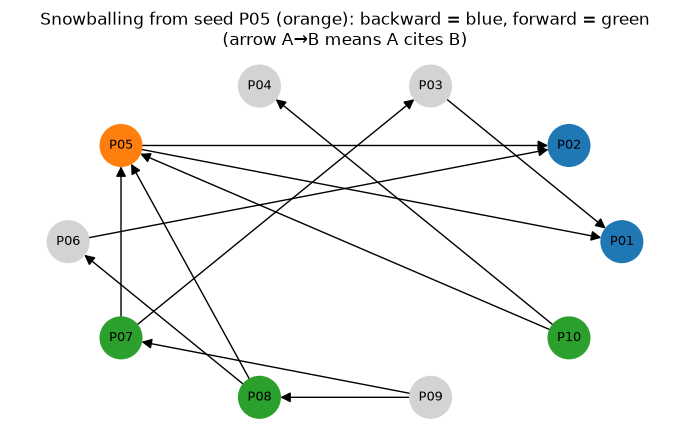

In [6]:
# A made-up citation graph: edge (A, B) means "paper A cites paper B"
G = nx.DiGraph()
G.add_edges_from([
    ("P05", "P01"), ("P05", "P02"), ("P07", "P05"), ("P07", "P03"), ("P08", "P05"),
    ("P09", "P07"), ("P09", "P08"), ("P10", "P05"), ("P10", "P04"), ("P06", "P02"),
    ("P08", "P06"), ("P03", "P01"),
])
seed = "P05"
backward = sorted(G.successors(seed))      # papers the seed cites (older)
forward = sorted(G.predecessors(seed))     # papers that cite the seed (newer)
print("seed:", seed, "| backward (references):", backward, "| forward (cited by):", forward)

# Iterate snowballing until nothing new appears (both directions)
found, frontier, rounds = {seed}, {seed}, 0
while frontier:
    rounds += 1
    new = set()
    for p in frontier:
        new |= set(G.successors(p)) | set(G.predecessors(p))   # one step back and forward
    frontier = new - found                                       # only papers we have not seen
    found |= frontier
    print(f"round {rounds}: new papers {sorted(frontier)}")
print("total found from one seed:", len(found), "of", G.number_of_nodes())

# Draw it: seed in orange, backward in blue, forward in green
colors = ["tab:orange" if n == seed else "tab:blue" if n in backward else "tab:green" if n in forward else "lightgray" for n in G.nodes]
pos = nx.circular_layout(sorted(G.nodes))       # papers in ID order around a circle
plt.figure(figsize=(7, 4.5))
nx.draw_networkx(G, pos, node_color=colors, node_size=900, font_size=9, arrows=True, arrowsize=15)
plt.title("Snowballing from seed P05 (orange): backward = blue, forward = green\n(arrow A→B means A cites B)")
plt.axis("off"); plt.tight_layout(); plt.show()

**What just happened?** From the seed P05, backward snowballing gives its references P01 and P02; forward snowballing gives the papers that cite it, P07, P08 and P10. Repeating the process reaches all 10 papers in 3 rounds (the last round adds nothing new, which is the stopping rule). On a real graph this is a breadth-first search, so it costs O(V + E) for V papers and E citations visited. In practice, you also apply your inclusion criteria at every step so the snowball does not grow forever.

## 4. Reading papers

> **In plain English:** Read papers in three passes, from a quick skim to a deep check, and learn to spot weak evidence.

### 4.1 The three-pass method (Keshav, 2007)

| Pass | Time | What you read | You should be able to answer |
|---|---|---|---|
| **1. Bird's-eye** | 5–10 min | title, abstract, introduction, section headings, conclusion, glance at figures and references | the **5 Cs**: Category (what type of paper?), Context (which papers is it related to?), Correctness (do the assumptions look valid?), Contributions, Clarity. Decide: keep reading or not? |
| **2. Content** | ~1 hour | the whole paper, carefully, but skip proofs; study figures, axes, error bars; mark unread references | summarise the main thrust with evidence to someone else |
| **3. Re-implementation (virtual)** | 4–5 h (beginners more) | everything, re-deriving each step, challenging every assumption | rebuild the paper from memory; list its hidden assumptions, missing citations, and possible flaws |

For a literature review you do pass 1 on many papers, pass 2 on the relevant ones and pass 3 on the 3–5 papers your thesis directly builds on.

### 4.2 A paper-summary template

Fill one per paper (in your reference manager's notes, or as code below so that summaries become rows of the literature matrix in Section 5).

In [7]:
@dataclass
class PaperSummary:
    key: str                        # citation key, e.g. "aziz2023urdufake"
    question: str                   # the research question in one sentence
    method: str                     # what they did
    data: str                       # datasets, size, language
    results: str                    # headline numbers WITH uncertainty if given
    evidence_quality: str           # e.g. "5 seeds + CI", "single run", "no baseline"
    limitations: str                # stated and unstated weaknesses
    relevance: str                  # how it relates to MY research question
    red_flags: list = field(default_factory=list)   # filled by the checker below

    def to_markdown(self):
        rows = [(k.replace("_", " "), v) for k, v in self.__dict__.items()]
        return "\n".join(f"- **{k}:** {v}" for k, v in rows)

example = PaperSummary(
    key="p03_fictional",
    question="Does back-translation augmentation improve Urdu fake-news detection?",
    method="Fine-tune a multilingual BERT with 3x back-translated data",
    data="Fictional 'UrduNews-2k' (2,000 articles), single random split",
    results="F1 0.91 vs 0.84 for TF-IDF+LR",
    evidence_quality="single run, no variance reported",
    limitations="test set of 200 articles; baseline not tuned",
    relevance="Same task as my thesis; tells me which baseline to beat",
)
print(example.to_markdown())

- **key:** p03_fictional
- **question:** Does back-translation augmentation improve Urdu fake-news detection?
- **method:** Fine-tune a multilingual BERT with 3x back-translated data
- **data:** Fictional 'UrduNews-2k' (2,000 articles), single random split
- **results:** F1 0.91 vs 0.84 for TF-IDF+LR
- **evidence quality:** single run, no variance reported
- **limitations:** test set of 200 articles; baseline not tuned
- **relevance:** Same task as my thesis; tells me which baseline to beat
- **red flags:** []


### 4.3 Spotting weak evidence

Use this checklist in pass 2. Each "yes" is a **red flag** that should lower your trust, not a reason to ignore the paper.

| Red flag | Why it matters |
|---|---|
| single run / no variance or CI | the gain may be seed noise (notebook 2, Section 6) |
| no or weak baseline (untuned, old) | gains shrink against strong, equally tuned baselines |
| tiny test set | 1% accuracy on 200 examples is 2 examples (notebook 2, power analysis) |
| test set used for model selection | optimistic numbers (test-set reuse) |
| no ablation | you cannot tell which component helps |
| claims beyond the data ("works for all languages") | external validity |
| no code / data / hyper-parameters | not reproducible |
| p-values without effect sizes, or many tests without correction | p-hacking risk (notebook 3) |
| only the best seed or best dataset shown | cherry-picking |

Below, a small rule-based checker turns this table into code so you can run it on every row of your literature matrix.

In [8]:
def red_flags(s: PaperSummary) -> list:
    text = " ".join([s.method, s.data, s.results, s.evidence_quality, s.limitations]).lower()
    rules = {
        "single run / no variance":  any(w in text for w in ["single run", "no variance", "one seed"]),
        "weak or untuned baseline":  any(w in text for w in ["not tuned", "untuned", "no baseline"]),
        "small test set":            bool(re.search(r"test set of (\d+)", text)) and int(re.search(r"test set of (\d+)", text).group(1)) < 1000,
        "single split, no CV":       "single random split" in text,
        "no uncertainty in results": re.search(r"±|\bci\b|\bstd\b|confidence", text) is None,
    }
    return [name for name, hit in rules.items() if hit]

example.red_flags = red_flags(example)
print(f"{len(example.red_flags)} red flags:", example.red_flags)

5 red flags: ['single run / no variance', 'weak or untuned baseline', 'small test set', 'single split, no CV', 'no uncertainty in results']


**What just happened?** The fictional paper raised all **5** red flags: one run, an untuned baseline, a 200-article test set, a single split and no uncertainty around "0.91 vs 0.84". With 200 test articles, one article is 0.5 percentage points, so a 7-point gap could still be real, but you cannot know without variance. This is exactly the kind of evidence you should *re-test* in your own thesis rather than copy as a fact.

## 5. The literature review matrix

> **In plain English:** Put every paper in one table so you can compare them side by side and see what is missing.

**Intuition.** A literature review is **not** a list of summaries ("A did X. B did Y. C did Z."). That is an *annotated bibliography*. A review **synthesises**: it groups papers by theme, compares them, and shows what is *missing* (the **research gap**) that your thesis will fill.

**Definition.** A **literature review matrix** (synthesis matrix) is a table with one row per paper and one column per attribute you want to compare (method, data, language, metric, result, evidence quality, limitations). Sorting, grouping and cross-tabulating it turns reading notes into a synthesis.

Below are **10 made-up papers** on low-resource fake-news detection. They are fictional, for practice only: do not cite them.

In [9]:
papers = pd.DataFrame([
    # id, first author (fictional), year, venue type, theme, language, method, data size, metric, score, seeds, human eval?, code?
    ("P01", "Aziz",     2018, "conference", "Classical ML",   "English",      "TF-IDF + SVM",               12000, "F1", 0.86, 1, False, False),
    ("P02", "Mbeki",    2019, "journal",    "Classical ML",   "Swahili",      "n-gram + logistic regression", 3000, "F1", 0.79, 1, False, True),
    ("P03", "Qureshi",  2020, "workshop",   "Augmentation",   "Urdu",         "mBERT + back-translation",   2000, "F1", 0.91, 1, False, False),
    ("P04", "Lindqvist",2020, "conference", "Transformers",   "Multilingual", "XLM-R fine-tuning",         40000, "F1", 0.88, 3, False, True),
    ("P05", "Haider",   2021, "conference", "Transformers",   "Urdu",         "XLM-R fine-tuning",          5000, "F1", 0.89, 5, False, True),
    ("P06", "Okafor",   2022, "journal",    "Augmentation",   "Swahili",      "LLM paraphrase augmentation", 3000, "F1", 0.83, 3, False, True),
    ("P07", "Raza",     2023, "conference", "Transformers",   "Urdu",         "Urdu-specific BERT",         5000, "F1", 0.90, 5, True,  True),
    ("P08", "Sato",     2023, "preprint",   "LLM prompting",  "English",      "GPT-style zero-shot",        1500, "F1", 0.81, 1, False, False),
    ("P09", "Iyer",     2024, "conference", "LLM prompting",  "Hindi",        "few-shot open LLM",          2500, "F1", 0.84, 3, True,  True),
    ("P10", "Nowak",    2025, "journal",    "LLM prompting",  "Multilingual", "LLM-as-judge verification",  8000, "F1", 0.86, 5, True,  True),
], columns=["id", "author", "year", "venue", "theme", "language", "method", "n_examples", "metric", "score", "seeds", "human_eval", "code"])
print(papers.to_string(index=False))

 id    author  year      venue         theme     language                       method  n_examples metric  score  seeds  human_eval  code
P01      Aziz  2018 conference  Classical ML      English                 TF-IDF + SVM       12000     F1   0.86      1       False False
P02     Mbeki  2019    journal  Classical ML      Swahili n-gram + logistic regression        3000     F1   0.79      1       False  True
P03   Qureshi  2020   workshop  Augmentation         Urdu     mBERT + back-translation        2000     F1   0.91      1       False False
P04 Lindqvist  2020 conference  Transformers Multilingual            XLM-R fine-tuning       40000     F1   0.88      3       False  True
P05    Haider  2021 conference  Transformers         Urdu            XLM-R fine-tuning        5000     F1   0.89      5       False  True
P06    Okafor  2022    journal  Augmentation      Swahili  LLM paraphrase augmentation        3000     F1   0.83      3       False  True
P07      Raza  2023 conference  Tr

In [10]:
# 1) Synthesis by theme: what does each line of work look like?
by_theme = papers.groupby("theme").agg(
    n_papers=("id", "count"),
    years=("year", lambda y: f"{y.min()}-{y.max()}"),
    languages=("language", lambda s: ", ".join(sorted(set(s)))),
    mean_score=("score", "mean"),
    median_seeds=("seeds", "median"),
    share_with_code=("code", "mean"),
).round(2)
print(by_theme.to_string())

# 2) Evidence quality across the field
print(f"\nPapers with a single run: {(papers.seeds == 1).sum()} of {len(papers)}")
print(f"Papers with human evaluation: {papers.human_eval.sum()} of {len(papers)}")

               n_papers      years                     languages  mean_score  median_seeds  share_with_code
theme                                                                                                      
Augmentation          2  2020-2022                 Swahili, Urdu        0.87           2.0             0.50
Classical ML          2  2018-2019              English, Swahili        0.82           1.0             0.50
LLM prompting         3  2023-2025  English, Hindi, Multilingual        0.84           3.0             0.67
Transformers          3  2020-2023            Multilingual, Urdu        0.89           5.0             1.00

Papers with a single run: 4 of 10
Papers with human evaluation: 3 of 10


**What just happened?** Grouping turns ten summaries into three *themes* you can write about as paragraphs:

- **Classical ML** (2 papers, 2018–2019, English and Swahili): strong but older baselines, single runs.
- **Augmentation and Transformers** (2 + 3 papers, 2020–2023): the highest scores, but the best number (0.91, P03) comes from a single run on 2,000 examples, the weakest evidence in the table.
- **LLM prompting** (3 papers, 2023–2025): newest, slightly lower scores, and the only theme where most papers include human evaluation.

Across the field, **4 of 10** papers report a single run and only **3 of 10** have human evaluation, a methodological gap in itself. Note that the scores come from *different datasets* and cannot be compared directly; a synthesis says so explicitly.

Now the classic gap-finding trick: **cross-tabulate two attributes** and look for empty cells.

language       English  Hindi  Multilingual  Swahili  Urdu
theme                                                     
Augmentation         0      0             0        1     1
Classical ML         1      0             0        1     0
LLM prompting        1      1             1        0     0
Transformers         0      0             1        0     2


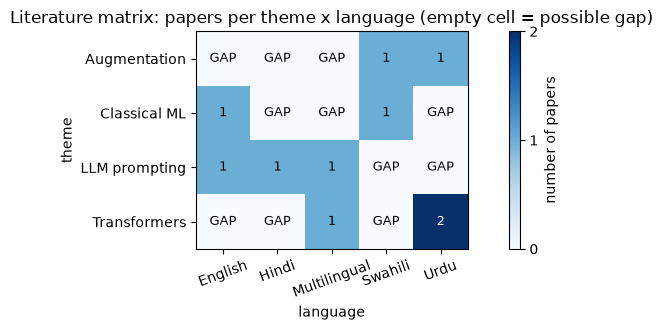

Empty cells: 11 -> e.g. [('Classical ML', 'Urdu'), ('LLM prompting', 'Urdu')]


In [11]:
gap = pd.crosstab(papers["theme"], papers["language"])           # count papers per (theme, language)
print(gap.to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.4))
im = ax.imshow(gap.values, cmap="Blues", vmin=0)
ax.set_xticks(range(gap.shape[1]), gap.columns, rotation=20)
ax.set_yticks(range(gap.shape[0]), gap.index)
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        v = gap.values[i, j]
        ax.text(j, i, v if v else "GAP", ha="center", va="center", color="black" if v < 2 else "white", fontsize=9)
ax.set_title("Literature matrix: papers per theme x language (empty cell = possible gap)")
ax.set_xlabel("language"); ax.set_ylabel("theme")
plt.colorbar(im, ax=ax, label="number of papers", ticks=[0, 1, 2]); plt.tight_layout(); plt.show()

empty = [(t, l) for t in gap.index for l in gap.columns if gap.loc[t, l] == 0]
print("Empty cells:", len(empty), "-> e.g.", [c for c in empty if c[1] == "Urdu"])

**What just happened?** 11 of the 20 cells are empty, so emptiness alone is not enough: (Classical ML, Urdu) is empty too, but a TF-IDF study for Urdu would add little in 2026. The interesting empty cell is **(LLM prompting, Urdu)**: three papers prompt LLMs for fake-news detection (English, Hindi, multilingual), but none do it for Urdu, while Urdu has strong fine-tuned transformer results (P05, P07). That suggests a candidate gap and research question:

> *"How does few-shot prompting of open LLMs compare with a fine-tuned Urdu BERT for Urdu fake-news detection, under equal compute budgets and with human evaluation of explanations?"*

⚠️ **Common mistake:** an empty cell is a *candidate* gap, not proof. It may be empty because the idea is pointless or because your search missed papers. Confirm by searching specifically for it (Section 3) and ask "would the answer matter?" (the I and R of FINER).

Finally, a **publication timeline** shows how the field moves over time.

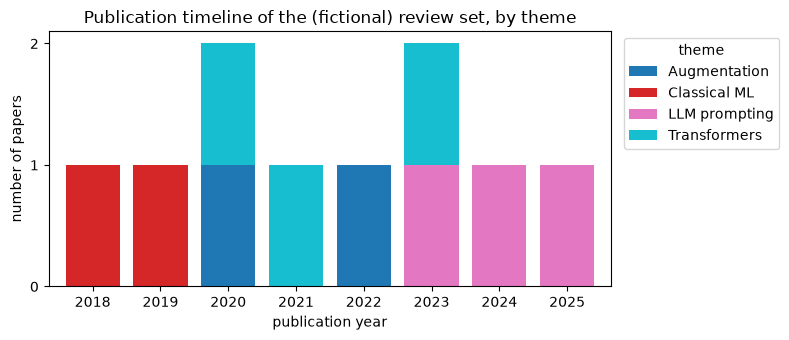

first LLM-prompting paper: 2023


In [12]:
timeline = pd.crosstab(papers["year"], papers["theme"])          # papers per year, split by theme
ax = timeline.plot(kind="bar", stacked=True, figsize=(8, 3.5), colormap="tab10", width=0.8)
ax.set_xlabel("publication year"); ax.set_ylabel("number of papers")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))     # whole papers only
ax.set_title("Publication timeline of the (fictional) review set, by theme")
ax.legend(title="theme", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("first LLM-prompting paper:", papers.loc[papers.theme == "LLM prompting", "year"].min())

**What just happened?** The stacked bars show the field's shift: classical ML in 2018–2019, transformers and augmentation in 2020–2023, and LLM prompting from 2023 onwards. In your review, this becomes one sentence with a figure: *"Since 2023, work has shifted from fine-tuning towards prompting large language models (Fig. X)."*

**How to write the review from the matrix:** one subsection per theme → within each, compare methods and evidence (not paper by paper) → a final "Summary and research gap" subsection that points to the empty cell and the weak-evidence pattern (single runs, no human evaluation) → your RQ.

## 6. Systematic reviews and PRISMA 2020

> **In plain English:** A systematic review follows a written recipe so anyone could find the same papers, and PRISMA shows the counts.

A normal (narrative) review can pick papers freely. A **systematic review** follows a **pre-defined, reported protocol** so that someone else running the same protocol would find the same papers. A **meta-analysis** goes one step further and statistically pools the numeric results.

Steps of a systematic review:
1. Write and (ideally) register a **protocol**: RQ, databases, search strings, inclusion/exclusion criteria, data to extract (health reviews register on PROSPERO; in CS, put it on OSF or in an appendix).
2. **Identify** records in each database (save the exact strings and dates).
3. Remove **duplicates**.
4. **Screen** titles and abstracts against the criteria (ideally two screeners, disagreements discussed, agreement measured with Cohen's kappa, see notebook 2).
5. Retrieve full texts and assess **eligibility**; record the reason for each exclusion.
6. **Include** studies, extract data (your literature matrix) and assess risk of bias.

**PRISMA 2020** (Page et al., *BMJ* 2021) is the reporting guideline: a 27-item checklist and the famous **flow diagram** of counts. The counts must add up, so let's compute them from (made-up) data instead of typing them by hand.

In [13]:
# Simulate records exported from four databases, with overlaps (duplicates)
db_sizes = {"Google Scholar": 180, "Semantic Scholar": 120, "ACL Anthology": 60, "arXiv": 90}
n_unique = 300                                                       # the "true" distinct papers
universe = pd.DataFrame({
    "doi": [f"10.9999/fict.{i:04d}" for i in range(n_unique)],       # fictional DOIs
    "year": rng.integers(2012, 2026, n_unique),
    "is_survey": rng.random(n_unique) < 0.08,
    "on_topic": rng.random(n_unique) < 0.35,                         # title/abstract relevance
    "full_text_ok": rng.random(n_unique) < 0.93,                     # can we get the PDF?
    "reports_metrics": rng.random(n_unique) < 0.70,                  # full-text eligibility
})
exports = []
for db, k in db_sizes.items():
    rows = universe.sample(k, random_state=len(db)).assign(source=db)   # each DB finds a subset
    exports.append(rows)
records_all = pd.concat(exports, ignore_index=True)

# --- PRISMA stages, each computed from the data ---
identified = len(records_all)
dedup = records_all.drop_duplicates("doi")
duplicates = identified - len(dedup)
screened = len(dedup)
excl_screen = dedup[~(dedup.on_topic & (dedup.year >= 2018) & ~dedup.is_survey)]
sought = dedup.drop(excl_screen.index)
not_retrieved = (~sought.full_text_ok).sum()
assessed = sought[sought.full_text_ok]
excl_full = assessed[~assessed.reports_metrics]
included = assessed[assessed.reports_metrics]

flow = {
    "Records identified": identified,
    "Duplicates removed": duplicates,
    "Records screened": screened,
    "Records excluded (title/abstract)": len(excl_screen),
    "Reports sought for retrieval": len(sought),
    "Reports not retrieved": int(not_retrieved),
    "Reports assessed for eligibility": len(assessed),
    "Reports excluded (no usable metrics)": len(excl_full),
    "Studies included in review": len(included),
}
for k, v in flow.items():
    print(f"{k:<40}{v:>5}")
print("per database:", records_all.source.value_counts().to_dict())

# The counts must be consistent: this is what reviewers check
assert identified - duplicates == screened
assert screened - len(excl_screen) == len(sought)
assert len(sought) - not_retrieved == len(assessed)
assert len(assessed) - len(excl_full) == len(included)
print("PRISMA arithmetic checks passed")

Records identified                        450
Duplicates removed                        197
Records screened                          253
Records excluded (title/abstract)         206
Reports sought for retrieval               47
Reports not retrieved                       4
Reports assessed for eligibility           43
Reports excluded (no usable metrics)       16
Studies included in review                 27
per database: {'Google Scholar': 180, 'Semantic Scholar': 120, 'arXiv': 90, 'ACL Anthology': 60}
PRISMA arithmetic checks passed


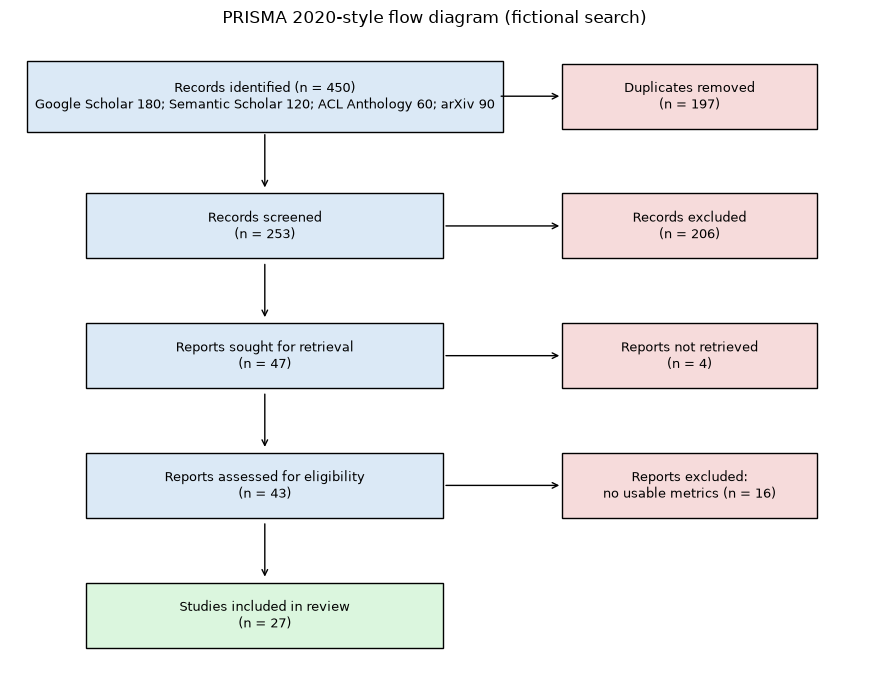

In [14]:
# Draw a simplified PRISMA 2020 flow diagram with matplotlib boxes and arrows
fig, ax = plt.subplots(figsize=(9, 7)); ax.axis("off")
ax.set_xlim(0, 10); ax.set_ylim(0, 10)
def box(x, y, text, w=4.2, h=1.0, color="#dbe9f6"):
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, facecolor=color, edgecolor="black"))
    ax.text(x, y, text, ha="center", va="center", fontsize=9)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->"))

per_db = "; ".join(f"{k} {v}" for k, v in db_sizes.items())
box(3, 9, f"Records identified (n = {identified})\n{per_db}", w=5.6, h=1.1)
box(8, 9, f"Duplicates removed\n(n = {duplicates})", w=3.0, color="#f6dbdb")
box(3, 7, f"Records screened\n(n = {screened})")
box(8, 7, f"Records excluded\n(n = {len(excl_screen)})", w=3.0, color="#f6dbdb")
box(3, 5, f"Reports sought for retrieval\n(n = {len(sought)})")
box(8, 5, f"Reports not retrieved\n(n = {not_retrieved})", w=3.0, color="#f6dbdb")
box(3, 3, f"Reports assessed for eligibility\n(n = {len(assessed)})")
box(8, 3, f"Reports excluded:\nno usable metrics (n = {len(excl_full)})", w=3.0, color="#f6dbdb")
box(3, 1, f"Studies included in review\n(n = {len(included)})", color="#dbf6de")
for y in (9, 7, 5, 3):
    arrow(3, y - 0.55, 3, y - 1.45)         # down to the next stage
    arrow(5.75 if y == 9 else 5.1, y, 6.5, y)   # right to the exclusion box
ax.set_title("PRISMA 2020-style flow diagram (fictional search)", fontsize=12)
plt.tight_layout(); plt.show()

**What just happened?** We exported 450 records from four databases, removed 197 duplicates (the same DOI found by several databases), screened the remaining 253 titles/abstracts and kept 47 for full-text retrieval. 4 PDFs could not be obtained and 16 of the 43 full texts had no usable metrics, leaving **27 included studies**. Every arrow's number was computed from the data and the asserts confirm the arithmetic, which is the most common error examiners find in PRISMA diagrams.

**Complexity:** de-duplicating N records with a hash on the DOI is O(N) expected time; in real exports many records lack a DOI, so you also compare normalised titles (lower-case, strip punctuation), which reference managers do for you.

> 🎓 **Exam / interview tip:** "What is the difference between a systematic review and a meta-analysis?" A systematic review is a *reproducible search and selection* protocol; a meta-analysis is a *statistical pooling* of results. You can have a systematic review without a meta-analysis (common in AI because papers use different datasets and metrics).

## 7. Reference managers and BibTeX

> **In plain English:** Let software store your papers and format your references, so you never type a citation by hand.

A **reference manager** stores PDFs, metadata and notes, and inserts citations into Word, Google Docs or LaTeX.

| Tool | Cost | Strengths | Watch out for |
|---|---|---|---|
| **Zotero** (7.x) | free, open source | browser connector saves a paper in one click; groups for sharing with your supervisor; **Better BibTeX** plugin keeps stable citation keys and auto-exports a `.bib` file for LaTeX/Overleaf | free cloud storage is small (300 MB) for PDFs; you can store PDFs locally |
| **Mendeley** (Elsevier) | free tier | Mendeley Reference Manager + Cite add-in for Word | the old Mendeley Desktop was retired in 2022; check export options before you commit |
| **JabRef** | free, open source | edits `.bib` files directly | less convenient for PDFs and Word |
| **EndNote** | paid (often via university) | common in health sciences | licence ends when you leave the university |

**BibTeX** is the plain-text format LaTeX uses for references. One entry looks like this:

```bibtex
@inproceedings{haider2021xlmr,
  author    = {Haider, Sana and Malik, Omar},
  title     = {Fine-tuning {XLM-R} for Urdu Fake News Detection},
  booktitle = {Proceedings of a Fictional Conference},
  year      = {2021},
  pages     = {101--110},
}
```

The first word after `@` is the **entry type** (`article`, `inproceedings`, `book`, `misc` for preprints...), then the **citation key** you use in `\cite{haider2021xlmr}`, then `field = {value}` pairs. Curly braces inside a title (`{XLM-R}`) protect capitalisation.

Let's write a small `.bib` file, parse it with a from-scratch parser, validate required fields, and format references.

In [15]:
bib_text = r'''
@inproceedings{haider2021xlmr,
  author    = {Haider, Sana and Malik, Omar},
  title     = {Fine-tuning {XLM-R} for Urdu Fake News Detection},
  booktitle = {Proceedings of a Fictional Conference},
  year      = {2021},
  pages     = {101--110},
}
@article{okafor2022para,
  author  = {Okafor, Chidi and Mbeki, Thandi and Lee, Ana},
  title   = {Paraphrase Augmentation with Language Models for Swahili Misinformation},
  journal = {Journal of Fictional Language Technology},
  year    = {2022},
  volume  = {7},
}
@misc{sato2023zeroshot,
  author = {Sato, Ken},
  title  = {Zero-shot Fake News Detection with Large Language Models},
  year   = {2023},
}
'''
REQUIRED = {"article": {"author", "title", "journal", "year"},
            "inproceedings": {"author", "title", "booktitle", "year"},
            "misc": {"author", "title", "year"}}

def parse_bibtex(text):
    entries = []
    for m in re.finditer(r"@(\w+)\s*\{\s*([^,\s]+)\s*,(.*?)\n\}", text, flags=re.S):   # one entry per match
        etype, key, body = m.group(1).lower(), m.group(2), m.group(3)
        fields = {f.lower(): v.strip() for f, v in re.findall(r"(\w+)\s*=\s*\{((?:[^{}]|\{[^{}]*\})*)\}", body)}
        entries.append({"type": etype, "key": key, **fields})
    return entries

def format_reference(e):
    # A simple author-year style: "Haider, S., & Malik, O. (2021). Title. Venue."
    names = [n.strip() for n in e["author"].split(" and ")]
    short = [f"{n.split(',')[0]}, {n.split(',')[1].strip()[0]}." for n in names]
    authors = short[0] if len(short) == 1 else ", ".join(short[:-1]) + ", & " + short[-1]
    title = e["title"].replace("{", "").replace("}", "")
    venue = e.get("journal") or e.get("booktitle") or "Preprint"
    return f"{authors} ({e['year']}). {title}. {venue}."

workdir = Path(tempfile.mkdtemp())                     # a temporary folder for the .bib file
bib_path = workdir / "references.bib"
bib_path.write_text(bib_text, encoding="utf-8")       # write it like a real project would
entries = parse_bibtex(bib_path.read_text(encoding="utf-8"))

for e in entries:
    missing = REQUIRED[e["type"]] - e.keys()           # set difference = missing required fields
    print(f"[{e['key']}] type={e['type']:<13} missing={sorted(missing) or 'none'}")
print()
for e in sorted(entries, key=lambda e: e["author"]):   # reference lists are usually alphabetical
    print(format_reference(e))
shutil.rmtree(workdir)                                 # clean up the temporary folder

[haider2021xlmr] type=inproceedings missing=none
[okafor2022para] type=article       missing=none
[sato2023zeroshot] type=misc          missing=none

Haider, S., & Malik, O. (2021). Fine-tuning XLM-R for Urdu Fake News Detection. Proceedings of a Fictional Conference.
Okafor, C., Mbeki, T., & Lee, A. (2022). Paraphrase Augmentation with Language Models for Swahili Misinformation. Journal of Fictional Language Technology.
Sato, K. (2023). Zero-shot Fake News Detection with Large Language Models. Preprint.


**What just happened?** The parser found 3 entries, all with their required fields (a `@misc` preprint only needs author, title and year, but you should add an `eprint`/`url` field and *upgrade it to the published version* once it appears). The formatter produced author-year references. In real life Zotero + Better BibTeX or the BibTeX export of dblp/ACL Anthology does this for you, but knowing the format helps you fix the broken entries that Google Scholar exports (wrong year, missing venue, lowercase acronyms).

> ⚠️ **Common mistake:** citing the arXiv version of a paper that was later published at a peer-reviewed venue. Examiners see this as careless; dblp shows both versions so you can cite the published one.

## 8. Research ethics

> **In plain English:** Give credit, get permission, never fake results, and use AI writing tools openly and carefully.

Ethics is not a box you tick at the end. Problems here can cost you the degree even if the experiments are excellent.

| Topic | Rule of thumb |
|---|---|
| **Plagiarism** | Using someone's words, ideas, figures, code or data without credit. Includes **self-plagiarism** (re-using your own published text without citing it) and **patchwriting** (changing a few words of someone else's sentence). Universities run similarity checkers (e.g. Turnitin, iThenticate); in Pakistan the HEC plagiarism policy applies to MS/MPhil and PhD theses. |
| **Citation** | Cite what you used *and actually read*. Quote exact words with quotation marks + citation. Cite the original source, not a blog that summarised it. Cite datasets and software too. |
| **Authorship** | Authors are people who made a substantial intellectual contribution *and* can take responsibility for the work (ICMJE-style criteria). Supervisors are usually co-authors of thesis papers; "gift" or "ghost" authorship is misconduct. **AI tools cannot be authors** (COPE and virtually all publishers and venues). |
| **Data consent and privacy** | Data about people needs a lawful basis and usually informed consent; respect platform terms and dataset licences; anonymise/pseudonymise; collect only what you need (data minimisation). See [privacy](../19_AI_Ethics_and_Safety/03_privacy.ipynb) and [copyright & AI](../19_AI_Ethics_and_Safety/06_copyright_and_ai.ipynb). |
| **IRB / ethics review** | Any study with human participants (interviews, user studies, annotators, crowdworkers) or personal data usually needs approval from your university's ethics committee (an **IRB** in the US, a research ethics committee elsewhere) **before** you collect data. Pay annotators fairly and let them stop at any time. |
| **Dual use** | Research that can help *and* harm (deepfake generators, jailbreak methods, surveillance). Many venues ask for a broader-impact or ethics statement; consider staged release and responsible disclosure. See [responsible AI](../19_AI_Ethics_and_Safety/04_responsible_ai.ipynb). |
| **Fabrication / falsification** | Inventing data or results, or changing them (including dropping "bad" seeds without reporting it). This is the most serious form of misconduct. |

### 8.1 Using AI writing assistants responsibly

Policies change every year, so **read the current call for papers and your university's policy** before each submission. As of 2026 the common ground across major AI venues (ACL/ARR, NeurIPS, ICML, ICLR) and publishers is:

1. **You are fully responsible** for everything in the paper: every claim, number, citation and line of code, whoever or whatever wrote the first draft.
2. **LLMs cannot be listed as authors**, because they cannot take responsibility.
3. **Disclose** substantial use (beyond spelling/grammar polishing), and describe it in the methods section when an LLM is part of the *method* (e.g. LLM-generated data or LLM-as-judge).
4. **Verify every reference.** Hallucinated or wrong citations are treated as an integrity failure, not a typo; several venues have desk-rejected papers for them.
5. **Reviewers must not paste confidential submissions** into third-party AI tools, and reviews must reflect the reviewer's own judgement.
6. For a thesis, your university may require a declaration of AI use; when in doubt, ask your supervisor *before* using a tool and keep a log of how you used it.

Similarity checkers work by comparing overlapping word sequences. The toy below measures the **Jaccard similarity of word 3-grams**, the core idea behind them.

In [16]:
def ngrams(text, n=3):
    words = re.findall(r"[a-z]+", text.lower())                 # lower-case words only
    return {tuple(words[i:i + n]) for i in range(len(words) - n + 1)}

def jaccard(a, b, n=3):
    A, B = ngrams(a, n), ngrams(b, n)
    return len(A & B) / len(A | B) if A | B else 0.0           # shared / total distinct n-grams

source = "Transformers fine-tuned on small Urdu datasets often overfit, so data augmentation is widely used to improve robustness."
copied = "Transformers fine-tuned on small Urdu datasets often overfit, so data augmentation is widely used to improve robustness."
patchwritten = "Transformers fine-tuned on small Urdu datasets frequently overfit, so data augmentation is commonly used to improve robustness."
own_words = "Because labelled Urdu text is scarce, models trained on it tend to memorise the training set; augmentation is one remedy (Qureshi, 2020)."
for name, t in [("verbatim copy", copied), ("patchwriting", patchwritten), ("own words + citation", own_words)]:
    print(f"{name:<22} 3-gram Jaccard = {jaccard(source, t):.2f}")

verbatim copy          3-gram Jaccard = 1.00
patchwriting           3-gram Jaccard = 0.45
own words + citation   3-gram Jaccard = 0.00


**What just happened?** The verbatim copy scores 1.00, **patchwriting** (swapping two words) still scores 0.45, and a genuine paraphrase with a citation scores 0.00. Patchwriting is still plagiarism *and* is easy to detect. The fix is to understand the idea, close the source, write it in your own words and cite it.

**Complexity:** building the n-gram sets is O(W) for W words; the set intersection is O(min(|A|, |B|)) on average with hashing. Real checkers index billions of documents with hashing tricks (fingerprinting / MinHash) so they do not compare against every document one by one.

## 9. The MS/MPhil proposal (synopsis)

> **In plain English:** The proposal is your thesis plan on paper, with a timeline that shows you can finish on time.

Most universities ask for a **research proposal** (often called a **synopsis** in South Asia) of about 8–20 pages before you start, defended in front of a committee. Exact headings differ, so always use your department's template; the structure below is the common core.

| # | Section | What it must contain | Typical length |
|---|---|---|---|
| 1 | **Title** | specific; contains the task, the method family and the population/data | 10–20 words |
| 2 | **Abstract** | problem, gap, aim, method, expected contribution | 150–250 words |
| 3 | **Introduction / background** | context, why the problem matters (with citations and numbers) | 1–2 pages |
| 4 | **Problem statement** | the specific problem and the gap in one or two paragraphs | 0.5 page |
| 5 | **Research questions, hypotheses, objectives** | RQs (FINER), H0/H1, SMART objectives | 0.5 page |
| 6 | **Significance and contributions** | who benefits; the novelty statement | 0.5 page |
| 7 | **Literature review** | synthesis by theme + gap (Section 5), ending with how your work differs | 3–6 pages |
| 8 | **Methodology** | research design, data (source, licence, consent, size), models and baselines, evaluation metrics, **statistical analysis plan** (notebooks 2–3), ethics approval | 2–4 pages |
| 9 | **Scope, delimitations and limitations** | what is in and out | 0.5 page |
| 10 | **Expected outcomes** | dataset, model, paper, software | short list |
| 11 | **Work plan / timeline** | Gantt chart with milestones | 1 figure |
| 12 | **Resources / budget** | compute (GPU hours), annotation cost, software | short table |
| 13 | **References** | consistent style (APA, IEEE or ACL) from your reference manager | 20–50 refs |

**A fill-in template you can copy:**

```
Title: <Task> for <data/population> using <method family>: <angle, e.g. "an equal-budget comparison">

Problem statement: Despite <progress>, <specific problem> remains because <reason>. Existing work
<limitation found in the literature matrix>. This leaves a gap: <the empty cell / weak-evidence pattern>.

RQ1: Does <X> improve <metric> over <baseline> on <data> under <conditions>?
H0: there is no difference in expected <metric> between <X> and <baseline>.  H1: <X> is higher.
Objectives: (1) To build ... by month m. (2) To compare ... (3) To analyse ...

Methodology: design = controlled experiment with k seeds and a fixed test split; baselines = trivial,
classical, prior SOTA re-run; tuning = equal budget of B trials per method; analysis = corrected
resampled t-test / bootstrap CI, Holm correction across RQs; ethics = approval ref. <number>.

Contributions: (1) ... (2) ... (3) code and data released under <licence>.
```

### 9.1 A timeline as a Gantt chart

A **Gantt chart** shows each task as a horizontal bar from its start to its end date. Committees look for realistic durations, overlaps (writing starts early!) and **milestones** (diamonds).

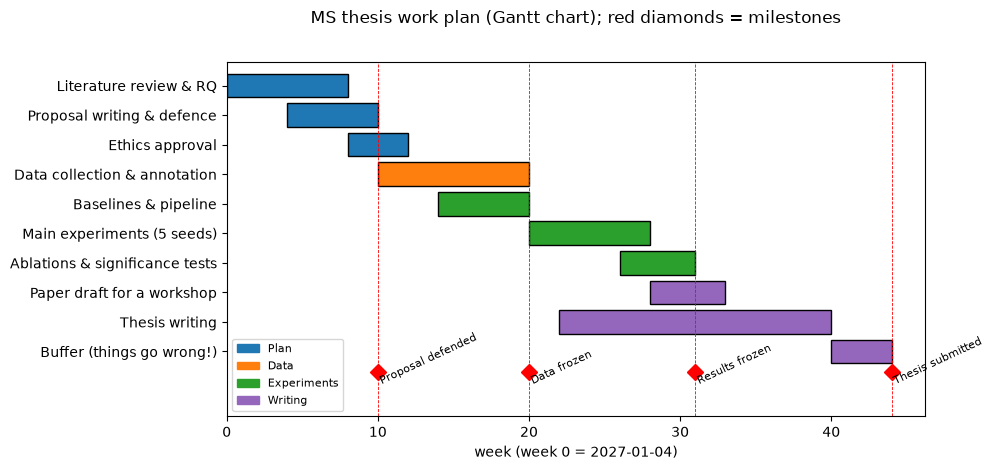

Total duration: 308 days, 0:00:00 -> ends 2027-11-08


In [17]:
start = date(2027, 1, 4)                                   # a made-up start date (first Monday of 2027)
tasks = [  # (task, start offset in weeks, duration in weeks, phase)
    ("Literature review & RQ",           0, 8,  "Plan"),
    ("Proposal writing & defence",       4, 6,  "Plan"),
    ("Ethics approval",                  8, 4,  "Plan"),
    ("Data collection & annotation",    10, 10, "Data"),
    ("Baselines & pipeline",            14, 6,  "Experiments"),
    ("Main experiments (5 seeds)",      20, 8,  "Experiments"),
    ("Ablations & significance tests",  26, 5,  "Experiments"),
    ("Paper draft for a workshop",      28, 5,  "Writing"),
    ("Thesis writing",                  22, 18, "Writing"),
    ("Buffer (things go wrong!)",       40, 4,  "Writing"),
]
milestones = [("Proposal defended", 10), ("Data frozen", 20), ("Results frozen", 31), ("Thesis submitted", 44)]
plan = pd.DataFrame(tasks, columns=["task", "start_wk", "dur_wk", "phase"])
plan["start"] = [start + timedelta(weeks=int(w)) for w in plan.start_wk]
plan["end"] = [s + timedelta(weeks=int(d)) for s, d in zip(plan.start, plan.dur_wk)]

colors = {"Plan": "tab:blue", "Data": "tab:orange", "Experiments": "tab:green", "Writing": "tab:purple"}
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, r in plan.iterrows():
    ax.barh(i, r.dur_wk, left=r.start_wk, color=colors[r.phase], edgecolor="black")   # one bar per task
for name, wk in milestones:
    ax.plot(wk, len(plan) - 0.3, marker="D", color="red", markersize=8)                # milestone diamond
    ax.axvline(wk, color="red", lw=0.6, ls="--")
    ax.text(wk, len(plan) + 0.1, name, rotation=25, fontsize=8, ha="left")
ax.set_yticks(range(len(plan)), plan.task); ax.invert_yaxis()
ax.set_xlabel(f"week (week 0 = {start.isoformat()})"); ax.set_ylim(len(plan) + 1.2, -0.8)
ax.set_title("MS thesis work plan (Gantt chart); red diamonds = milestones", pad=28)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
print(f"Total duration: {plan.end.max() - start} -> ends {plan.end.max().isoformat()}")

**What just happened?** Each task is a bar from its start week; the red dashed lines are milestones. The plan lasts **44 weeks (308 days)**, about ten months, ending in November 2027. Note three realistic details: thesis *writing starts in week 22*, long before experiments end; *ethics approval* sits before data collection; and there is a 4-week **buffer** at the end, because data collection and debugging always take longer than planned.

## 10. 🔗 How this connects to modern AI

> **In plain English:** The same habits keep you sane in today's flood of AI papers and leaderboards.

- **Literature at LLM speed.** cs.CL, cs.LG and cs.AI together receive thousands of new arXiv submissions every month. Boolean searches, snowballing and a literature matrix are how you keep a review *reproducible* when AI search assistants give different answers every time you ask.
- **Leaderboards are not literature.** With Papers with Code gone, "state of the art" lives on scattered leaderboards (LMArena, MTEB, SWE-bench, Hugging Face pages). Treat them like papers: who ran it, on what data, with what uncertainty, and is the test set contaminated? Notebook 2 covers benchmark overfitting.
- **Reading reviews on OpenReview** teaches you the criteria ICLR/NeurIPS reviewers apply (baselines, ablations, significance), exactly what notebooks 2–3 teach.
- **LLMs as research assistants** can draft search strings, summarise papers or suggest related work, but you must verify every claim and reference (Section 8.1). An LLM-assisted systematic review still needs the PRISMA counts and the human screening decisions.
- Related notebooks: [LLM evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb), [responsible AI](../19_AI_Ethics_and_Safety/04_responsible_ai.ipynb), [A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) (the industry version of an experiment), [causal inference](../03_Machine_Learning/10_causal_inference/01_causal_inference.ipynb) (explanatory research with observational data).

## Recap

- Research is **systematic, new and verifiable**. Classify a study on four axes: purpose (basic/applied), data (quantitative/qualitative/mixed), evidence (empirical/theoretical) and depth (exploratory/descriptive/explanatory).
- A good RQ passes **FINER** and names population, intervention, comparison and outcome. Hypotheses (H0/H1) are testable predictions; objectives are SMART actions; the contribution statement lists what is new.
- Search several databases with **Boolean concept blocks**, record strings and dates, then **snowball** backward and forward. Papers with Code shut down in 2025; arXiv preprints are not peer reviewed.
- Read with the **three-pass method**, summarise with a template, and flag weak evidence (single runs, weak baselines, tiny test sets, no ablation).
- A **literature matrix** turns summaries into a synthesis: group by theme, cross-tabulate to find gaps, plot the timeline.
- **Systematic reviews** follow a protocol; **PRISMA 2020** reports the flow counts, which must add up.
- Use a **reference manager** and clean **BibTeX**; cite the published version.
- **Ethics:** no plagiarism (including patchwriting), honest authorship, consent and ethics approval, dual-use awareness, and responsible, disclosed use of AI writing tools with every reference verified.
- A **proposal** has a fixed core structure; plan it with a **Gantt chart** that includes a buffer.

## Practice problems

**1. (Easy, conceptual)** Classify this study on the four axes: *"We prove a lower bound on the sample complexity of in-context learning for linear regression."*

<details><summary>Show solution</summary>

Purpose: **basic** (understanding, no product). Data: **quantitative** (mathematical quantities). Evidence: **theoretical** (a proof). Depth: **explanatory** (it explains *why/how much* data is needed). If the paper also ran simulations to illustrate the bound, it would be theoretical with empirical support.
</details>

**2. (Easy)** Rewrite the RQ *"Is deep learning good for crop disease detection?"* so that it passes FINER and names P, I, C and O.

<details><summary>Show solution</summary>

One good answer: *"Does a fine-tuned EfficientNet-B0 achieve higher macro-F1 than a colour-histogram + random-forest baseline on smartphone photos of wheat leaves from Punjab farms (held-out farms as the test set), and is the difference statistically significant over 5 seeds?"* P = smartphone photos of wheat leaves from Punjab farms; I = fine-tuned EfficientNet-B0; C = histogram + random forest; O = macro-F1. It is feasible (small model, one crop), novel (local data, held-out farms) and relevant (farmers' phones).
</details>

**3. (Medium, coding)** Using the `parse`, `tokenize` and `matches` functions above, write a query that finds records about **misinformation or fake news** that are **not about English** and test it on `records`. Which IDs match?

<details><summary>Show solution</summary>

```python
q = '("fake news" OR misinformation) AND NOT English'
t = parse(tokenize(q))
print(records.loc[[matches(t, s.lower()) for s in records.text], "id"].tolist())   # ['R1', 'R2', 'R3', 'R4']
```
R5 is excluded because it mentions English; R6 has neither concept.
</details>

**4. (Medium, coding)** Add a column `strong_evidence` to `papers` that is `True` when a paper has at least 3 seeds **and** released code. Which theme has the highest share of strong-evidence papers?

<details><summary>Show solution</summary>

```python
papers["strong_evidence"] = (papers.seeds >= 3) & papers.code
print(papers.groupby("theme").strong_evidence.mean().sort_values(ascending=False))
```
Transformers: 1.00 (P04, P05, P07); LLM prompting: 0.67; Augmentation: 0.50; Classical ML: 0.00.
</details>

**5. (Medium, conceptual)** A PRISMA diagram reports: 600 identified, 150 duplicates, 420 screened. What is wrong?

<details><summary>Show solution</summary>

600 − 150 = 450, so 450 records should have been screened, not 420. Either 30 records were removed without a reason (e.g. automation tools or non-English records), which must be reported as a separate box, or the counts are wrong. PRISMA 2020 has a box for "records removed for other reasons" exactly for this.
</details>

**6. (Medium, conceptual)** Your friend asks an LLM for "10 papers on Urdu fake-news detection with BibTeX" and pastes the result into their thesis. List three risks and the correct workflow.

<details><summary>Show solution</summary>

Risks: (1) **non-existent or wrong references** (hallucinated titles, wrong authors/years/venues); (2) citing papers **not read**, so claims may be misattributed; (3) violating the university/venue **AI-use policy** if undisclosed. Correct workflow: use the LLM only for ideas, then search Google Scholar/Semantic Scholar/ACL Anthology, open each paper, add it via Zotero (or dblp/ACL BibTeX), read at least pass 1, and disclose substantive AI use as the policy requires.
</details>

**7. (Hard, coding)** Write `forward_backward(G, seed, depth)` that returns the set of papers reachable within `depth` snowballing rounds (both directions) from `seed`. Check that depth 1 from P05 gives 5 papers and depth 3 gives all 10.

<details><summary>Show solution</summary>

```python
def forward_backward(G, seed, depth):
    found, frontier = {seed}, {seed}
    for _ in range(depth):
        nxt = set()
        for p in frontier:
            nxt |= set(G.successors(p)) | set(G.predecessors(p))
        frontier = nxt - found
        found |= frontier
    return found - {seed}

assert len(forward_backward(G, "P05", 1)) == 5     # P01, P02, P07, P08, P10
assert len(forward_backward(G, "P05", 3)) == 9     # every other paper (10 including the seed)
```
</details>

**8. (Hard, design)** Your Gantt chart has data annotation (10 weeks) starting before ethics approval is granted. Why is this a problem and how do you fix the plan?

<details><summary>Show solution</summary>

Annotation with human workers usually needs ethics approval *before* any data collection; data collected without approval may be unusable and is a misconduct risk. Fix: make annotation depend on the "ethics approved" milestone (finish-to-start dependency), use the waiting time for pipeline/baseline work on public data, and keep a buffer in case the committee asks for changes.
</details>

In [18]:
# Check the code solutions of the practice problems actually work
q = '("fake news" OR misinformation) AND NOT English'
t = parse(tokenize(q))
sol3 = records.loc[[matches(t, s.lower()) for s in records.text], "id"].tolist()
assert sol3 == ["R1", "R2", "R3", "R4"], sol3

papers["strong_evidence"] = (papers.seeds >= 3) & papers.code
sol4 = papers.groupby("theme").strong_evidence.mean().sort_values(ascending=False).round(2)
assert sol4.to_dict() == {"Transformers": 1.0, "LLM prompting": 0.67, "Augmentation": 0.5, "Classical ML": 0.0}, sol4

def forward_backward(G, seed, depth):
    found, frontier = {seed}, {seed}
    for _ in range(depth):
        nxt = set()
        for p in frontier:
            nxt |= set(G.successors(p)) | set(G.predecessors(p))
        frontier = nxt - found
        found |= frontier
    return found - {seed}
assert len(forward_backward(G, "P05", 1)) == 5
assert len(forward_backward(G, "P05", 3)) == 9
print("All practice-problem solutions verified:", sol3, sol4.to_dict())

All practice-problem solutions verified: ['R1', 'R2', 'R3', 'R4'] {'Transformers': 1.0, 'LLM prompting': 0.67, 'Augmentation': 0.5, 'Classical ML': 0.0}


## Further reading

- J. Zobel, *Writing for Computer Science*, 3rd ed., Springer, 2014: chapters on research questions, reading and the literature.
- J. W. Creswell & J. D. Creswell, *Research Design: Qualitative, Quantitative, and Mixed Methods Approaches*, 6th ed., SAGE, 2023: research types and paradigms.
- S. B. Hulley et al., *Designing Clinical Research*, 4th ed., 2013: the FINER criteria and the PICO idea.
- S. Keshav, "How to Read a Paper", *ACM SIGCOMM Computer Communication Review*, 2007 (free PDF, 2 pages).
- C. Wohlin, "Guidelines for snowballing in systematic literature studies", EASE 2014.
- M. J. Page et al., "The PRISMA 2020 statement", *BMJ* 2021; checklist and flow-diagram templates at prisma-statement.org.
- B. Kitchenham & S. Charters, *Guidelines for performing Systematic Literature Reviews in Software Engineering*, 2007 (the standard SLR guide in computing).
- Free online: the Zotero documentation (zotero.org/support) and the ACL Rolling Review "Responsible NLP Research" checklist.

## Next notebook

➡️ [02 – Experiment design for ML](02_experiment_design_for_ml.ipynb): turn your research question into a fair, convincing experiment.